# Dimensions: From UCSF Research Grants to Associated Patents

Dimensions connects several kinds of research and innovation information, including grants, publications, researchers, organizations, and patents.

In this workbook, we will investigate one relationship:

> Can we find UCSF grants in a research area and then identify patents that Dimensions associates with those grants?

We will:

- connect to the Dimensions API
- search for UCSF grants in a selected research area
- inspect the returned grant records
- collect their Dimensions grant IDs
- use those IDs to find associated patents
- create a pandas DataFrame
- make a simple visualization of the linked patents

The goal is to understand how identifiers and relationships in Dimensions allow us to move between different kinds of research and innovation information.


## 1. Setup

This notebook uses the `dimcli` Python package to communicate with the Dimensions API.

Access to the Dimensions API requires an API key and appropriate Dimensions access through your institution.

Store your API key in a `config.yml` file in the same directory as the notebook:

```yaml
dimensions_api_key: YOUR_DIMENSIONS_API_KEY
```

Do not commit `config.yml` or other files containing API keys to a public repository.


In [5]:
import yaml
import pandas as pd
import matplotlib.pyplot as plt
import dimcli

with open("config.yml", "r") as f:
    config = yaml.safe_load(f)

API_KEY = config["dimensions_api_key"]

dimcli.login(
    key=API_KEY,
    endpoint="https://app.dimensions.ai"
)

dsl = dimcli.Dsl()


Dimcli - Dimensions API Client (v1.8)
Connected to: <https://app.dimensions.ai/api/dsl> - DSL v2.16
Method: manual login


## 2. Choose a Research Area

Dimensions classifies grants using Fields of Research.

Use the Dimensions web interface to identify a `category_for` research-area label that interests you, then enter that label below.

For example, you might choose an area related to machine learning, artificial intelligence, cancer, neuroscience, or another UCSF research area.

Use the classification label exactly as it appears in Dimensions.


In [6]:
RESEARCH_AREA = "4611 Machine Learning"


## 3. Search for UCSF Grants

Now search for grants that meet two conditions:

- the research organization is the University of California, San Francisco
- the grant is classified in the selected research area

This narrows the search before we look for patent relationships.


In [8]:
grant_query = f'''
search grants
where research_org_names = "University of California, San Francisco"
and category_for.name = "{RESEARCH_AREA}"
return grants[
    id
    + title
    + funder_org_name
    + funding_usd
    + start_date
    + end_date
    + research_org_names
    + category_for
]
limit 1000
'''

grant_result = dsl.query(grant_query)

print(
    "Grant records returned:",
    len(grant_result.grants)
)


Returned Grants: 157 (total = 157)
Time: 0.73s
Grant records returned: 157


## 4. Inspect the Grant Results

Look at the returned grant records before moving on.


In [9]:
grant_result.grants[:5]


[{'category_for': [{'id': '80017',
    'name': '46 Information and Computing Sciences'},
   {'id': '80003', 'name': '32 Biomedical and Clinical Sciences'},
   {'id': '80052', 'name': '3209 Neurosciences'},
   {'id': '80190', 'name': '4611 Machine Learning'}],
  'end_date': '2029-08-31',
  'funder_org_name': 'National Institute of Mental Health',
  'funding_usd': 49956.0,
  'id': 'grant.15603099',
  'research_org_names': ['University of California, San Francisco'],
  'start_date': '2026-09-01',
  'title': 'Mechanisms and Function of Dendritic Integration in Cerebellar Granule Cells'},
 {'category_for': [{'id': '80017',
    'name': '46 Information and Computing Sciences'},
   {'id': '80003', 'name': '32 Biomedical and Clinical Sciences'},
   {'id': '80190', 'name': '4611 Machine Learning'}],
  'end_date': '2029-08-31',
  'funder_org_name': 'National Institute of Mental Health',
  'funding_usd': 43479.0,
  'id': 'grant.15603091',
  'research_org_names': ['University of California, San Fra

Convert the grants to a pandas DataFrame so they are easier to inspect.


In [10]:
grants_df = grant_result.as_dataframe()

grants_df.head()


,id,title,category_for,end_date,funder_org_name,funding_usd,research_org_names,start_date
0,grant.15603099,Mechanisms and Function of Dendritic Integrati...,"[{'id': '80017', 'name': '46 Information and C...",2029-08-31,National Institute of Mental Health,49956.0,"[University of California, San Francisco]",2026-09-01
1,grant.15603091,Towards a multimodal model of neuronal diversi...,"[{'id': '80017', 'name': '46 Information and C...",2029-08-31,National Institute of Mental Health,43479.0,"[University of California, San Francisco]",2026-09-01
2,grant.15555354,Collaborative Research: CRCNS Research Proposa...,"[{'id': '80017', 'name': '46 Information and C...",2030-08-31,"Directorate for Social, Behavioral & Economic ...",264556.0,"[University of California, San Francisco]",2026-09-01
3,grant.15529310,Dissecting neural circuits regulating sleep fr...,"[{'id': '80017', 'name': '46 Information and C...",2031-06-30,National Institute of Neurological Disorders a...,238680.0,"[University of California, San Francisco]",2026-07-15
4,grant.15477934,CRCNS Research Proposal: Computational and Neu...,"[{'id': '80197', 'name': '4704 Linguistics'}, ...",2031-06-30,"Directorate for Social, Behavioral & Economic ...",2043141.0,"[University of California, San Francisco]",2026-07-15


Look at the grant titles and funders.


In [11]:
grants_df[
    [
        "id",
        "title",
        "funder_org_name",
        "start_date",
        "end_date"
    ]
].head(20)


,id,title,funder_org_name,start_date,end_date
0,grant.15603099,Mechanisms and Function of Dendritic Integrati...,National Institute of Mental Health,2026-09-01,2029-08-31
1,grant.15603091,Towards a multimodal model of neuronal diversi...,National Institute of Mental Health,2026-09-01,2029-08-31
2,grant.15555354,Collaborative Research: CRCNS Research Proposa...,"Directorate for Social, Behavioral & Economic ...",2026-09-01,2030-08-31
3,grant.15529310,Dissecting neural circuits regulating sleep fr...,National Institute of Neurological Disorders a...,2026-07-15,2031-06-30
4,grant.15477934,CRCNS Research Proposal: Computational and Neu...,"Directorate for Social, Behavioral & Economic ...",2026-07-15,2031-06-30
5,grant.15529877,Defining area-specific cellular and circuit-le...,National Eye Institute,2026-07-01,2031-03-31
6,grant.15475614,Neural mechanisms of memory consolidation in t...,National Institute of Mental Health,2026-06-01,2030-05-31
7,grant.15320809,Neural computations underlying flexible contro...,National Institute of Mental Health,2026-05-22,2028-04-30
8,grant.15197889,Tracking Hidden Epidemics: A Phylodynamic Fram...,Deutsche Forschungsgemeinschaft,2026-01-01,NaN
9,grant.15123415,How does myelin plasticity influence neural ci...,National Institute of Mental Health,2025-11-01,2028-10-31


## 5. Collect the Grant IDs

Dimensions assigns each grant a unique identifier.

We can use these IDs to follow the relationship from grants to patents.


In [12]:
grant_ids = [
    grant["id"]
    for grant in grant_result.grants
]

grant_ids[:10]


['grant.15603099',
 'grant.15603091',
 'grant.15555354',
 'grant.15529310',
 'grant.15477934',
 'grant.15529877',
 'grant.15475614',
 'grant.15320809',
 'grant.15197889',
 'grant.15123415']

## 6. Find Patents Associated With These Grants

Dimensions patent records can contain an `associated_grant_ids` field.

We can therefore search for patents whose associated grant IDs include one of the UCSF grants returned above.


In [13]:
if not grant_ids:
    raise ValueError(
        "No grants were returned. "
        "Try another Dimensions research-area classification."
    )

ids = ", ".join(
    f'"{grant_id}"'
    for grant_id in grant_ids
)

patent_query = f'''
search patents
where associated_grant_ids in [{ids}]
return patents[
    id
    + title
    + filing_date
    + publication_date
    + granted_date
    + inventor_names
    + assignee_names
    + legal_status
    + cpc
    + associated_grant_ids
]
limit 1000
'''

patent_result = dsl.query(patent_query)

print(
    "Patent records returned:",
    len(patent_result.patents)
)


Returned Patents: 13 (total = 13)
Time: 0.52s
Patent records returned: 13


## 7. Inspect the Patent Results

Look at a few of the returned patent records.


In [14]:
patent_result.patents[:5]


[{'assignee_names': ['Us Government - Department Of Veterans Affairs',
   'United States Department of Veterans Affairs',
   'University of California, San Diego'],
  'associated_grant_ids': ['grant.2562737', 'grant.3535979'],
  'cpc': ['A61M5/1723',
   'A61N1/0531',
   'A61N1/0534',
   'A61N1/36067',
   'A61N1/36139'],
  'filing_date': '2016-03-21',
  'granted_date': '2017-03-28',
  'id': 'US-9604056-B2',
  'inventor_names': ['STARR PHILIP A',
   'DE HEMPTINNE CORALIE',
   'OSTREM JILL',
   'SWANN NICOLE'],
  'legal_status': 'Active',
  'publication_date': '2017-03-28',
  'title': 'Methods and systems for treating neurological movement disorders'},
 {'assignee_names': ['United States Department of Veterans Affairs',
   'University of California, San Diego'],
  'associated_grant_ids': ['grant.2562737', 'grant.3535979'],
  'cpc': ['A61M5/1723',
   'A61N1/0531',
   'A61N1/0534',
   'A61N1/36067',
   'A61N1/36139'],
  'filing_date': '2013-10-31',
  'granted_date': '2016-03-29',
  'id': 'U

Print the titles of the associated patents.


In [15]:
for patent in patent_result.patents:
    print(patent.get("title"))


Methods and systems for treating neurological movement disorders
Methods and systems for treating neurological movement disorders
Method of Contextual Speech Decoding From the Brain
Methods And Devices For Real-Time Word And Speech Decoding From Neural Activity
Methods for Culturing Cancer Cells and for Inhibiting Invasion of Cancer
Method of Contextual Speech Decoding from the Brain
Methods and Systems for Treating Neurological Movement Disorders
Methods and Systems for Treating Neurological Movement Disorders
Methods and Systems for Treating Neurological Movement Disorders
Adaptive Set Discrimination Procedure
Method of contextual speech decoding from the brain
Methods and systems for treating neurological movement disorders
Method of contextual speech decoding from the brain


The central relationship in this workbook is now visible:

```text
UCSF + research area
        ↓
      grants
        ↓
Dimensions grant IDs
        ↓
associated patent records
```

Dimensions allows us to move between different kinds of records by following relationships represented in the database.


## 8. Create a pandas DataFrame

Convert the patent records into a DataFrame.


In [16]:
patents_df = patent_result.as_dataframe()

patents_df.head()


,id,title,assignee_names,associated_grant_ids,cpc,filing_date,granted_date,inventor_names,legal_status,publication_date
0,US-9604056-B2,Methods and systems for treating neurological ...,[Us Government - Department Of Veterans Affair...,"[grant.2562737, grant.3535979]","[A61M5/1723, A61N1/0531, A61N1/0534, A61N1/360...",2016-03-21,2017-03-28,"[STARR PHILIP A, DE HEMPTINNE CORALIE, OSTREM ...",Active,2017-03-28
1,US-9295838-B2,Methods and systems for treating neurological ...,"[United States Department of Veterans Affairs,...","[grant.2562737, grant.3535979]","[A61M5/1723, A61N1/0531, A61N1/0534, A61N1/360...",2013-10-31,2016-03-29,"[STARR PHILIP A, DE HEMPTINNE CORALIE, OSTREM ...",Active,2016-03-29
2,US-20250252958-A1,Method of Contextual Speech Decoding From the ...,"[University of California, San Diego]","[grant.2355433, grant.6500252]","[A61B5/024, A61B5/372, A61B5/4064, A61F4/00, G...",2025-03-18,NaN,"[CHANG EDWARD F, MOSES DAVID A]",Granted,2025-08-07
3,US-20240366157-A1,Methods And Devices For Real-Time Word And Spe...,"[University of California, San Diego]",[grant.6500252],"[A61B5/24, A61B5/291, A61B5/293, A61B5/369, A6...",2022-05-26,NaN,"[MOSES DAVID A, LIU JESSIE, METZGER SEAN, CHAN...",Pending,2024-11-07
4,US-20230204565-A1,Methods for Culturing Cancer Cells and for Inh...,"[University of California, San Diego]","[grant.6500033, grant.4897748]","[A61P35/00, C12N2501/15, C12N2501/415, C12N250...",2020-12-23,NaN,"[BHADURI APARNA, DI LULLO ELIZABETH, KRIEGSTEI...",Abandoned,2023-06-29


Inspect the size and columns of the patent dataset.


In [17]:
patents_df.shape


(13, 10)

In [18]:
patents_df.columns


Index(['id', 'title', 'assignee_names', 'associated_grant_ids', 'cpc',
       'filing_date', 'granted_date', 'inventor_names', 'legal_status',
       'publication_date'],
      dtype='object')

Select a few fields that are easy to interpret.


In [19]:
patents_df[
    [
        "id",
        "title",
        "filing_date",
        "inventor_names",
        "assignee_names",
        "legal_status"
    ]
].head(20)


,id,title,filing_date,inventor_names,assignee_names,legal_status
0,US-9604056-B2,Methods and systems for treating neurological ...,2016-03-21,"[STARR PHILIP A, DE HEMPTINNE CORALIE, OSTREM ...",[Us Government - Department Of Veterans Affair...,Active
1,US-9295838-B2,Methods and systems for treating neurological ...,2013-10-31,"[STARR PHILIP A, DE HEMPTINNE CORALIE, OSTREM ...","[United States Department of Veterans Affairs,...",Active
2,US-20250252958-A1,Method of Contextual Speech Decoding From the ...,2025-03-18,"[CHANG EDWARD F, MOSES DAVID A]","[University of California, San Diego]",Granted
3,US-20240366157-A1,Methods And Devices For Real-Time Word And Spe...,2022-05-26,"[MOSES DAVID A, LIU JESSIE, METZGER SEAN, CHAN...","[University of California, San Diego]",Pending
4,US-20230204565-A1,Methods for Culturing Cancer Cells and for Inh...,2020-12-23,"[BHADURI APARNA, DI LULLO ELIZABETH, KRIEGSTEI...","[University of California, San Diego]",Abandoned
5,US-20220301563-A1,Method of Contextual Speech Decoding from the ...,2020-07-27,"[CHANG EDWARD F, MOSES DAVID A]","[University of California, San Diego]",Granted
6,US-20180353759-A1,Methods and Systems for Treating Neurological ...,2016-06-03,"[STARR PHILIP A, SWANN NICOLE, DE HEMPTINNE CO...","[University of California, San Diego]",Granted
7,US-20160263380-A1,Methods and Systems for Treating Neurological ...,2016-03-21,"[STARR PHILIP A, DE HEMPTINNE CORALIE, OSTREM ...",[Us Government - Department Of Veterans Affair...,Granted
8,US-20140163627-A1,Methods and Systems for Treating Neurological ...,2013-10-31,"[STARR PHILIP A, DE HEMPTINNE CORALIE, OSTREM ...","[United States Department of Veterans Affairs,...",Granted
9,US-20130203027-A1,Adaptive Set Discrimination Procedure,2011-06-22,"[DE VILLERS-SIDANI ETIENNE, MERZENICH MICHAEL]","[University of California, San Diego]",Abandoned


## 9. Which Grants Are Linked to the Most Patent Records?

A patent can be associated with more than one grant.

Count how often each grant ID appears in the returned patent records.


In [20]:
linked_grants = (
    patents_df["associated_grant_ids"]
    .explode()
    .value_counts()
    .rename_axis("grant_id")
    .reset_index(name="patent_records")
)

linked_grants.head(10)


,grant_id,patent_records
0,grant.6500252,5
1,grant.2562737,4
2,grant.2355433,4
3,grant.3535979,2
4,grant.3859283,2
5,grant.6500033,1
6,grant.4897748,1
7,grant.2440962,1


Add the grant titles so the results are easier to interpret.


In [21]:
grant_titles = grants_df[
    ["id", "title"]
].rename(
    columns={
        "id": "grant_id",
        "title": "grant_title"
    }
)

linked_grants = linked_grants.merge(
    grant_titles,
    on="grant_id",
    how="left"
)

linked_grants.head(10)


,grant_id,patent_records,grant_title
0,grant.6500252,5,Functional Architecture of Speech Motor Cortex
1,grant.2562737,4,Cortical and basal ganglia local field potenti...
2,grant.2355433,4,NaN
3,grant.3535979,2,Cortical and basal ganglia local field potenti...
4,grant.3859283,2,The motor network in Parkinson's disease: Mech...
5,grant.6500033,1,Development and Expansion of the Human Cerebra...
6,grant.4897748,1,NaN
7,grant.2440962,1,Variation as a Neural Code


## 10. Visualize the Grant-Patent Links

Plot the grants with the most linked patent records in this result set.


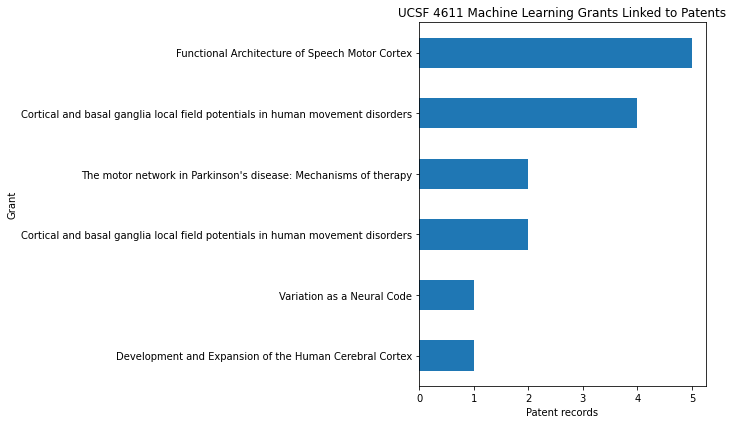

In [22]:
top_grants = (
    linked_grants
    .dropna(subset=["grant_title"])
    .head(10)
    .sort_values("patent_records")
)

top_grants.plot(
    kind="barh",
    x="grant_title",
    y="patent_records",
    legend=False,
    figsize=(10, 6)
)

plt.xlabel("Patent records")
plt.ylabel("Grant")
plt.title(
    f"UCSF {RESEARCH_AREA} Grants Linked to Patents"
)
plt.tight_layout()
plt.show()


## 11. Try Another Research Area

Change:

```python
RESEARCH_AREA = "..."
```

to another Field of Research classification from Dimensions and rerun the notebook.

Different research areas may return:

- many UCSF grants but few associated patents
- a small number of grants with many patent records
- no associated patents at all

Those differences are themselves useful information about the data and the research area being investigated.


## What We Did

In this workbook, we:

- searched Dimensions for UCSF grants in a selected research area
- inspected grant metadata
- collected Dimensions grant IDs
- followed those IDs into the patent data source
- retrieved associated patent records
- organized the results with pandas
- visualized which grants were linked to the most patent records

The important idea is not the particular research area used in the example. It is the ability to move between different kinds of research information using identifiers and relationships represented in Dimensions.
